# 7957 – Data Mining and Machine Learning

## Individual Assignment – Bank Marketing Dataset


- **Author**: Anaïs FERREIRA (EDHEC Business School)
- **Date**: 2025-11-27  

This notebook follows:

1. **Part I – Descriptive Analysis** of a public dataset (Bank Marketing from the UCI repository / Kaggle).  
2. **Part II – Machine Learning Techniques**: one **classification** model and one **clustering** model, with proper preprocessing, cross-validation, visualizations and explanations.


## 0. Dataset Description and Justification

I selected the **Bank Marketing** dataset (named `bank-additional-full.csv`). It contains data about
direct marketing campaigns of a Portuguese bank institution, where the goal is to predict whether a client
will subscribe to a term deposit.

**Why this dataset fits the assignment requirements:**

- It is **publicly available** on the UCI Machine Learning Repository and Kaggle.  
- It contains **more than 5,000 instances** (over 40,000 rows).  
- It contains **more than 15 features** (demographic, socio-economic and campaign-related variables).  
- It supports at least **two different tasks**:
  - **Classification**: predict whether the client subscribed to the term deposit (`y` variable: yes/no).  
  - **Clustering**: perform unsupervised **customer segmentation** to understand groups of similar clients.

From a business perspective, this dataset is interesting because it addresses a classic **marketing analytics**
problem: improving campaign efficiency by targeting the right customers.


## 1. Setup and Data Loading

In this section we import the required Python libraries and load the dataset.



In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

pd.set_option('display.max_columns', 50)

# Data: download "bank-additional.zip" from the UCI repository (see README)
# and place bank-additional-full.csv in ./data/
csv_path = Path("data") / "bank-additional-full.csv"

# Load the dataset
df = pd.read_csv(csv_path, sep=';')
print("Shape:", df.shape)
print("Columns:", list(df.columns))

df.head()


Shape: (41188, 21)
Columns: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### 1.1 Basic Structure of the Dataset

We start by looking at the shape, data types and presence of missing values.


In [47]:
print('Shape (rows, columns):', df.shape)
print('\nData types:')
print(df.dtypes)

print('\nNumber of missing values per column:')
print(df.isna().sum())

Shape (rows, columns): (41188, 21)

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Number of missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx 

The dataset contains several **categorical features** (such as `job`, `marital`, `education`, `contact`, etc.)
and **numeric features** (such as `age`, `campaign`, `duration`, `previous`, `euribor3m`, `nr.employed`).
There are no explicit missing values (they are often encoded as `'unknown'` for some categorical variables).


## Part I – Descriptive Analysis

In this part we perform **univariate** and **bivariate** analysis of the dataset, and we create
several visualizations to better understand the data.


### 2.1 Univariate Statistics – Numeric Features

We start with summary statistics (mean, std, min, max, quartiles) for the numeric variables.


In [28]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


The table above shows the distribution of numeric features. For example:

- `age` typically ranges from young adults to older clients.  
- `campaign` indicates the number of contacts during this campaign and is often skewed
  (a few clients receive many calls).  
- `duration` is the last contact duration in seconds and is very unevenly distributed.

These insights already hint that some features may need **transformation** or at least
careful interpretation (e.g., `duration` is known to be very predictive but not usable
for real-time campaign planning, because it is only known after the call).


> **Note on `duration`:** the call duration is only known after the call, so it would not be available to plan a real campaign. It is kept here as in the original dataset documentation, but a production model should exclude it.

### 2.2 Histograms for Selected Numeric Variables

We plot histograms for a subset of numeric variables to visualize their distributions.


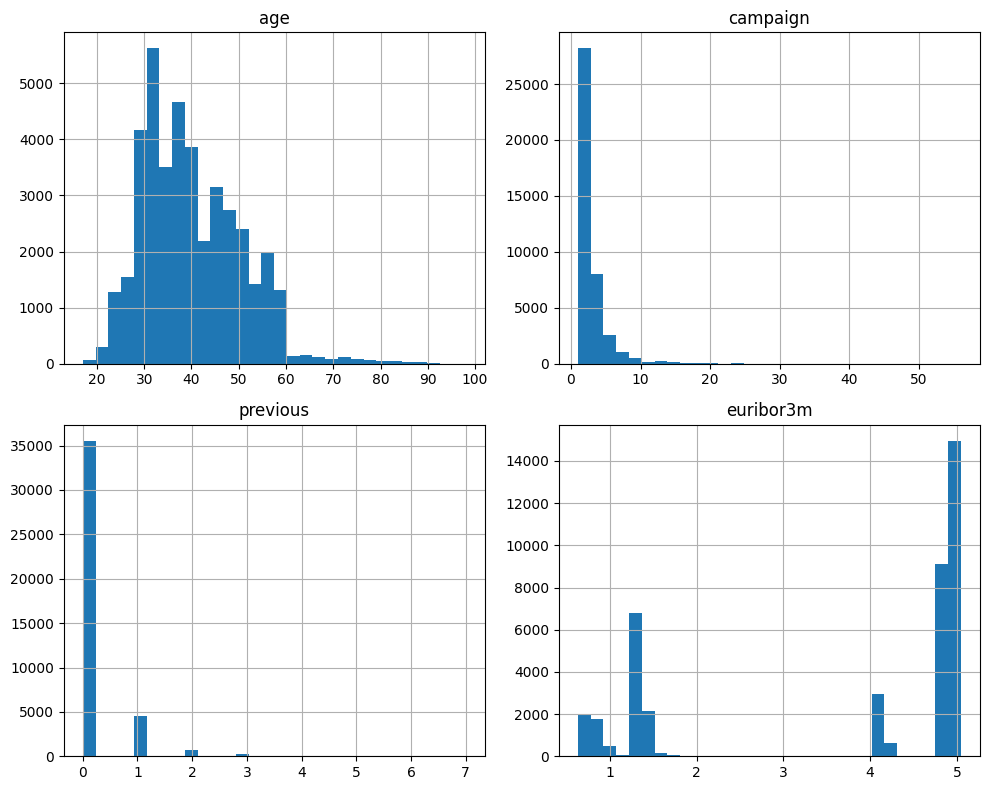

In [29]:
numeric_to_plot = ['age', 'campaign', 'previous', 'euribor3m']
df[numeric_to_plot].hist(bins=30, figsize=(10, 8))
plt.tight_layout()
plt.show()

**Comments:**

- `age` is slightly right-skewed: there are fewer very young and very old clients.  
- `campaign` is highly skewed with many clients contacted only a few times and a small
  number contacted very frequently.  
- `previous` (number of contacts before this campaign) has many zeros.  
- `euribor3m` (3-month Euribor rate) reflects the macroeconomic context during the campaign.


### 2.3 Univariate Statistics – Categorical Features

We now look at the frequency distribution of some categorical features and of the target variable `y`.


In [30]:
categorical_cols = df.select_dtypes(include=['object']).columns
categorical_cols

Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')

Target counts:
 y
no     36548
yes     4640
Name: count, dtype: int64

Target proportions:
 y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


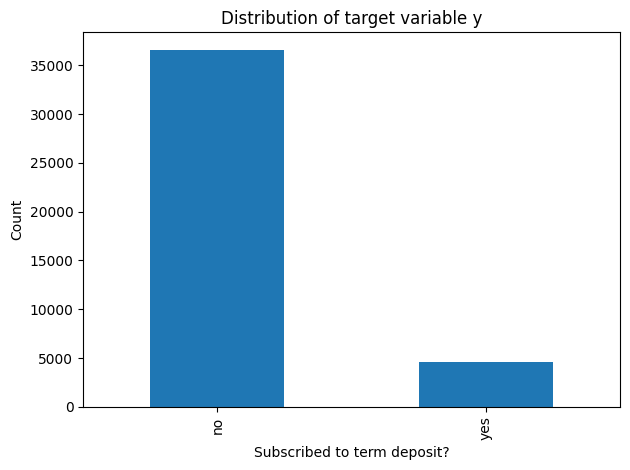

In [48]:
target_counts = df['y'].value_counts(normalize=False)
target_ratio = df['y'].value_counts(normalize=True)
print('Target counts:\n', target_counts)
print('\nTarget proportions:\n', target_ratio)

fig, ax = plt.subplots()
target_counts.plot(kind='bar', ax=ax)
ax.set_title('Distribution of target variable y')
ax.set_xlabel('Subscribed to term deposit?')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

The target variable `y` is **highly imbalanced**: most clients did **not** subscribe to the term deposit.
This class imbalance will be important when evaluating classification models (we should not rely only
on accuracy but also consider metrics such as **precision**, **recall**, **F1-score** and **ROC AUC**).


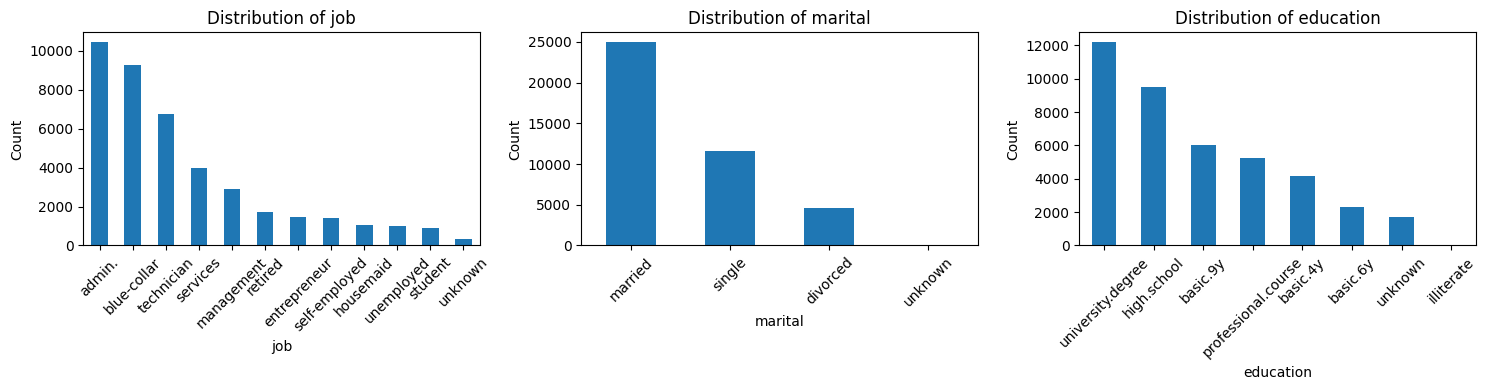

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ['job', 'marital', 'education']):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

The bar plots show that some categories (for example certain jobs or education levels) are much more
frequent than others. This will influence how the model learns and may require **regularization**
or careful handling of rare categories.


### 2.4 Bivariate Analysis – Correlations between Numeric Features

We compute the **correlation matrix** for numeric variables and visualize it.


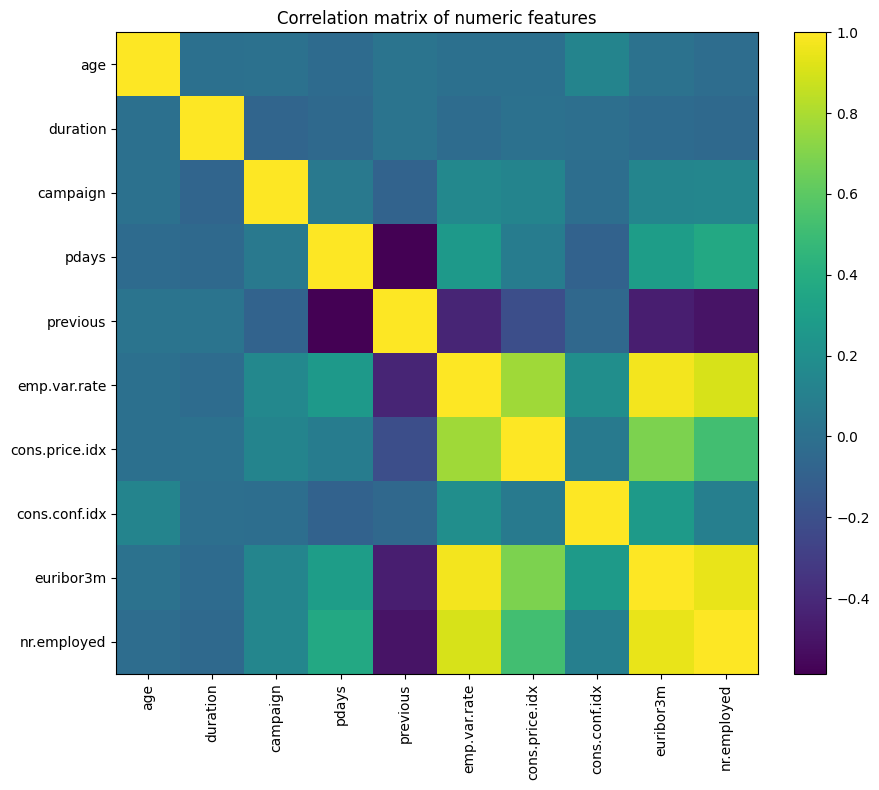

In [33]:
corr_matrix = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix.values)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=90)
ax.set_yticklabels(numeric_cols)
ax.set_title('Correlation matrix of numeric features')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

We observe several pairs of **strongly correlated variables**, such as `euribor3m` and `nr.employed`,
because both reflect the macroeconomic situation. Highly correlated variables may cause issues for
some models (e.g. linear models), so regularization or feature selection can be useful.


### 2.5 Relationship between Selected Features and the Target `y`

We now explore how some features relate to the probability of subscription.


y
no     39.911185
yes    40.913147
Name: age, dtype: float64

Subscription rate by job:
job
student          0.314286
retired          0.252326
unemployed       0.142012
admin.           0.129726
management       0.112175
unknown          0.112121
technician       0.108260
self-employed    0.104856
housemaid        0.100000
entrepreneur     0.085165
services         0.081381
blue-collar      0.068943
Name: y, dtype: float64


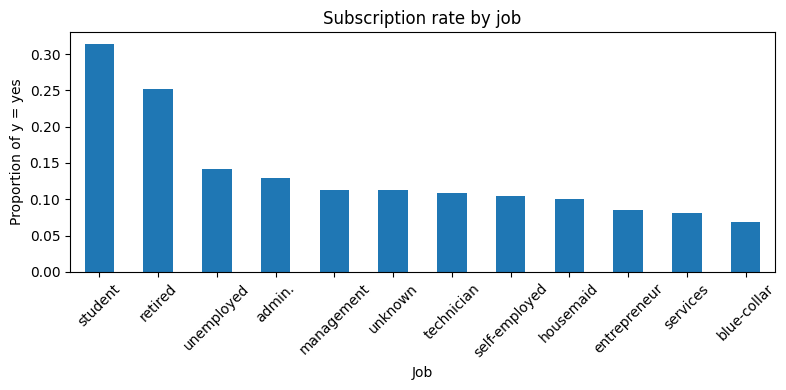

In [34]:
# Mean age by target class
print(df.groupby('y')['age'].mean())

# Subscription rate by job
subscription_rate_job = df.groupby('job')['y'].apply(lambda x: (x == 'yes').mean())
print('\nSubscription rate by job:')
print(subscription_rate_job.sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
subscription_rate_job.sort_values(ascending=False).plot(kind='bar', ax=ax)
ax.set_title('Subscription rate by job')
ax.set_xlabel('Job')
ax.set_ylabel('Proportion of y = yes')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

We see that some professions are associated with **higher subscription rates** than others. This suggests
that socio-economic characteristics can play an important role in explaining customer behavior.


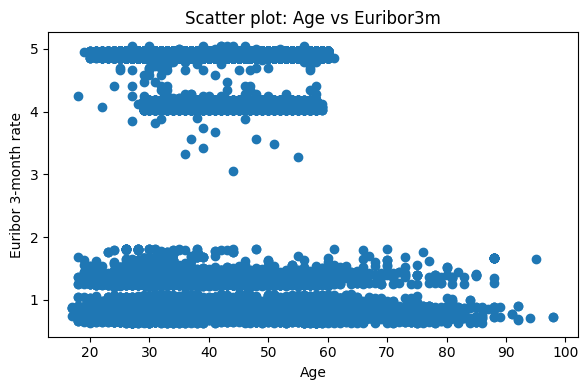

In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df['age'], df['euribor3m'])
ax.set_xlabel('Age')
ax.set_ylabel('Euribor 3-month rate')
ax.set_title('Scatter plot: Age vs Euribor3m')
plt.tight_layout()
plt.show()

This scatter plot illustrates the joint distribution of `age` and `euribor3m`. There is no obvious
linear relationship between those two variables, which is expected because one is an individual
characteristic and the other is a macroeconomic indicator.


## Part II – Machine Learning Techniques

In this part we apply two types of machine learning analyses:

1. **Supervised classification** using **Logistic Regression** to predict whether a client subscribes
   to a term deposit.  
2. **Unsupervised clustering** using **K-Means** to segment clients into groups with similar profiles.

Both tasks are relevant for the Bank Marketing dataset:

- **Classification** is directly aligned with the campaign objective (predicting subscription).  
- **Clustering** helps the bank understand different customer segments and tailor marketing strategies
  to each group.


### 3.1 Preprocessing

We first separate features and target, and build a preprocessing pipeline to:

- **One-hot encode** categorical variables.  
- **Standardize** numeric variables (zero mean, unit variance).  

This is important because many models (such as logistic regression and K-Means) are sensitive to the
scale of the input features.


In [36]:
X = df.drop(columns=['y'])
y = (df['y'] == 'yes').astype(int)  # 1 for yes, 0 for no

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((32950, 20), (8238, 20))

We use a **stratified** train–test split to preserve the class imbalance ratio in both sets.
The `preprocessor` object will be reused in both the classification and clustering steps.


### 3.2 Classification with Logistic Regression

We now build a **Pipeline** combining the preprocessing step and a **Logistic Regression** classifier.
Logistic Regression is a common baseline for binary classification because it is:

- Interpretable (coefficients indicate the direction of the effect of each feature).  
- Efficient on large datasets.  
- Easy to regularize (to avoid overfitting).


In [37]:
log_reg_clf = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=1000, n_jobs=-1))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_auc = cross_val_score(log_reg_clf, X_train, y_train, cv=cv, scoring='roc_auc')
cv_f1 = cross_val_score(log_reg_clf, X_train, y_train, cv=cv, scoring='f1')

print('Cross-validated ROC AUC (train):', cv_auc.mean(), '+/-', cv_auc.std())
print('Cross-validated F1-score (train):', cv_f1.mean(), '+/-', cv_f1.std())

Cross-validated ROC AUC (train): 0.9330887340501486 +/- 0.004029623435701503
Cross-validated F1-score (train): 0.5072952649454733 +/- 0.00917306122905044


Using **5-fold cross-validation** on the training set, we obtain estimates of model performance that
are less optimistic than a single train–test split and help reduce the risk of **overfitting**.


In [38]:
log_reg_clf.fit(X_train, y_train)

y_pred = log_reg_clf.predict(X_test)
y_proba = log_reg_clf.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_proba)

print('Test accuracy:', acc)
print('Test precision:', prec)
print('Test recall:', rec)
print('Test F1-score:', f1)
print('Test ROC AUC:', auc)

print('\nClassification report:\n')
print(classification_report(y_test, y_pred))

Test accuracy: 0.9166059723233795
Test precision: 0.7117750439367311
Test recall: 0.4364224137931034
Test F1-score: 0.5410821643286573
Test ROC AUC: 0.9424372906740885

Classification report:

              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7310
           1       0.71      0.44      0.54       928

    accuracy                           0.92      8238
   macro avg       0.82      0.71      0.75      8238
weighted avg       0.91      0.92      0.91      8238



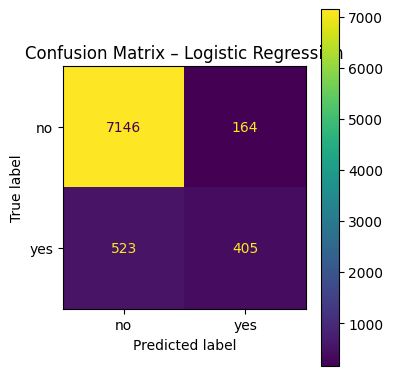

In [39]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax)
ax.set_title('Confusion Matrix – Logistic Regression')
plt.tight_layout()
plt.show()

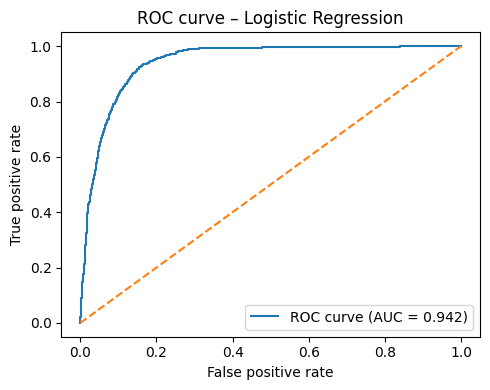

In [40]:
fpr, tpr, thresholds = roc_curve(y_test, y_proba)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(fpr, tpr, label=f'ROC curve (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_title('ROC curve – Logistic Regression')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Interpretation of the classification results:**

- Because the dataset is **imbalanced**, accuracy alone can be misleading.  
- The **recall** on the positive class (subscribed clients) is particularly important from a business
  perspective: missing a potential subscriber might mean a lost opportunity.  
- The **ROC AUC** summarizes the trade-off between true positive rate and false positive rate across all
  possible classification thresholds.


### 3.3 Interpreting Logistic Regression Coefficients

To interpret the model, we extract the learned coefficients and map them back to the corresponding features.
This tells us which variables increase or decrease the log-odds of subscription.


In [41]:
log_reg_model = log_reg_clf.named_steps['model']
pre = log_reg_clf.named_steps['preprocess']

feature_names_num = numeric_features
feature_names_cat = pre.named_transformers_['cat'].named_steps['encoder'].get_feature_names_out(categorical_features)
all_feature_names = np.concatenate([feature_names_num, feature_names_cat])

coef = log_reg_model.coef_[0]
importance = pd.Series(coef, index=all_feature_names).sort_values(ascending=False)

importance.head(15)

month_mar               1.640903
duration                1.199467
cons.price.idx          1.177989
euribor3m               0.610467
month_aug               0.509778
job_retired             0.324348
nr.employed             0.286991
education_illiterate    0.215058
poutcome_success        0.210278
job_student             0.132872
cons.conf.idx           0.085991
month_sep               0.028831
month_dec               0.015917
day_of_week_wed        -0.002601
age                    -0.004545
dtype: float64

Positive coefficients indicate features associated with a **higher probability of subscription**, while
negative coefficients indicate features associated with a **lower probability**. This information
can guide marketers in understanding which customer characteristics are most relevant.


### 3.4 Clustering with K-Means

We now perform an **unsupervised clustering** analysis using **K-Means**. The goal is to identify groups of
clients with similar profiles, which can later be used for **customer segmentation**.

We will:

1. Build a numeric, standardized feature matrix using the same preprocessing as before.  
2. Use an **elbow plot** to choose a reasonable number of clusters.  
3. Fit a K-Means model and interpret the resulting clusters.


In [42]:
# Build a preprocessed feature matrix for clustering (using the entire dataset)
X_preprocessed = preprocessor.fit_transform(X)
X_preprocessed.shape

(41188, 63)

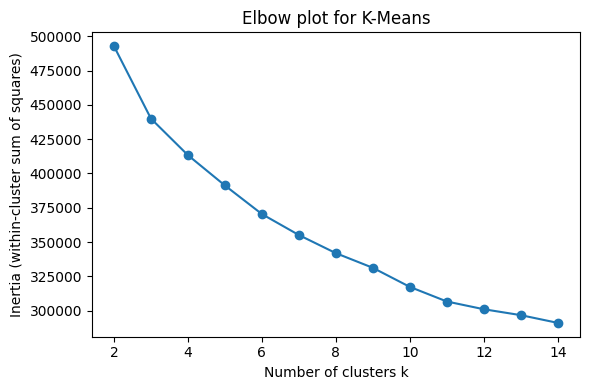

In [43]:
inertias = []
cluster_range = range(2, 15)

for k in cluster_range:
    kmeans_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_tmp.fit(X_preprocessed)
    inertias.append(kmeans_tmp.inertia_)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(cluster_range), inertias, marker='o')
ax.set_xlabel('Number of clusters k')
ax.set_ylabel('Inertia (within-cluster sum of squares)')
ax.set_title('Elbow plot for K-Means')
plt.tight_layout()
plt.show()

The elbow plot helps us choose a value of **k** where adding more clusters does not significantly reduce
the inertia. For illustration, we choose **k = 3** clusters.


In [44]:
k_opt = 3
kmeans = KMeans(n_clusters=k_opt, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_preprocessed)
df_clusters = df.copy()
df_clusters['cluster'] = clusters
df_clusters['y_binary'] = y

df_clusters['cluster'].value_counts().sort_index()

cluster
0    27646
1    12006
2     1536
Name: count, dtype: int64

In [45]:
cluster_profile_numeric = df_clusters.groupby('cluster')[numeric_cols].mean()
cluster_profile_subscription = df_clusters.groupby('cluster')['y_binary'].mean()

print('Average numeric features by cluster:\n')
display(cluster_profile_numeric)

print('\nSubscription rate (proportion of y = 1) by cluster:\n')
print(cluster_profile_subscription)

Average numeric features by cluster:



,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
cluster,,,,,,,,,,
0,40.192505,252.384685,2.800875,999.000000,0.025248,1.117771,93.843821,-39.456996,4.818460,5213.418328
1,39.394719,263.646427,2.125021,999.000000,0.318841,-2.025496,92.986962,-43.187098,1.202028,5077.932575
2,41.911458,322.576172,1.828125,19.590495,1.691406,-2.090560,93.350723,-38.338997,0.983738,5028.680664



Subscription rate (proportion of y = 1) by cluster:

cluster
0    0.048289
1    0.194320
2    0.632812
Name: y_binary, dtype: float64


**Interpretation of the clusters:**

The three clusters are mainly separated by the **macroeconomic context** and the **client's contact history**:

- **Cluster 0 (27,646 clients, 4.8% subscription)**: clients contacted when rates were high (Euribor ≈ 4.8%, positive employment variation), almost never contacted before (`pdays` = 999). This is the largest and least responsive segment.
- **Cluster 1 (12,006 clients, 19.4% subscription)**: clients contacted in a low-rate environment (Euribor ≈ 1.2%), still mostly new contacts. A difficult economic context makes the term deposit more attractive.
- **Cluster 2 (1,536 clients, 63.3% subscription)**: clients **already contacted in a previous campaign** (`pdays` ≈ 20 days, 1.7 previous contacts on average) with longer calls. This small segment is by far the most responsive.

From a marketing perspective, the bank should prioritise follow-ups with clients already reached in previous campaigns (cluster 2), and time large campaigns according to the interest-rate context rather than increasing the number of calls.

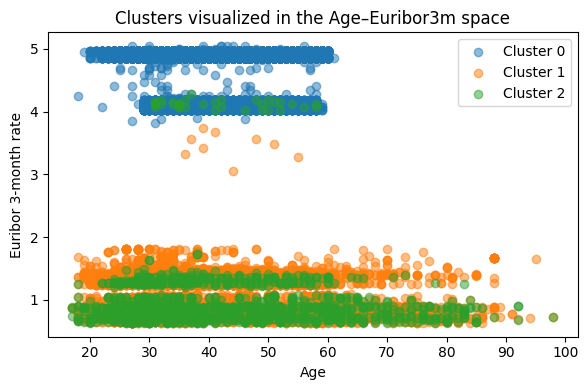

In [46]:
# 2D visualization of clusters on two numeric variables
fig, ax = plt.subplots(figsize=(6, 4))

for cluster_id in sorted(df_clusters['cluster'].unique()):
    subset = df_clusters[df_clusters['cluster'] == cluster_id]
    ax.scatter(subset['age'], subset['euribor3m'], label=f'Cluster {cluster_id}', alpha=0.5)

ax.set_xlabel('Age')
ax.set_ylabel('Euribor 3-month rate')
ax.set_title('Clusters visualized in the Age–Euribor3m space')
ax.legend()
plt.tight_layout()
plt.show()

This plot shows a projection of the clusters in a two-dimensional space (`age` vs `euribor3m`).
Although the real clustering is done in a much higher-dimensional space, such visualizations help build
intuition about the structure of the data.


## 4. Discussion and Conclusion

### Why these analyses are interesting for this dataset

- The **classification task** directly addresses the bank's business question: _which clients are most
  likely to subscribe to a term deposit?_ Logistic Regression provides both reasonable predictive
  performance and interpretability.
- The **clustering task** provides a complementary perspective by uncovering **customer segments** with
  different profiles and subscription rates. This unsupervised view can reveal patterns that are not
  obvious from the classification model alone.

### Why these methods were chosen

- **Logistic Regression** was chosen over more complex models (such as random forests or gradient boosting)
  because it is:
  - Easier to interpret.  
  - Fast and robust on large, high-dimensional datasets.  
  - A good baseline to compare against more complex models in future work.
- **K-Means** was chosen for clustering because it is a simple and widely used algorithm that scales well
  to large datasets and works naturally with standardized numeric features.

### Key concepts used

- **Feature scaling / standardization**: applied to numeric features to give them comparable scales for both
  logistic regression and K-Means.  
- **One-hot encoding** of categorical variables: required to use them in most ML algorithms.
- **Cross-validation**: used to obtain robust estimates of classification performance and mitigate overfitting.  
- **Class imbalance handling**: we monitored metrics such as recall, F1-score and ROC AUC instead of relying
  only on accuracy.

### Possible extensions

- Try more advanced models (Random Forest, Gradient Boosting, XGBoost) and compare their performance.  
- Use techniques to explicitly address class imbalance (class weights, resampling).  
- Perform feature selection or regularization analysis to simplify the model.  
- Explore alternative clustering methods (e.g., hierarchical clustering, DBSCAN) and more sophisticated
  methods for choosing the number of clusters.

Overall, this notebook demonstrates a complete workflow from **descriptive statistics** to **supervised
and unsupervised learning**, with clear reasoning and visualizations that support the conclusions.
